# Naira Pulse, Stage 2: Feature Engineering & Target Definition

**Picks up from Stage 1's output:** `processed_data/naira_pulse_master.csv`

**This notebook:**
1. Loads the merged dataset from Stage 1
2. Confronts something the raw data itself revealed: a structural break in June 2023, and decides how to handle it
3. Engineers lag, rolling, and calendar features
4. Defines the classification target (will the naira weaken more than 1% over the next 7 trading days)
5. Checks the class balance, on the full history and on the window that actually matters, and explains why they differ
6. Saves a clean, model-ready dataset for Stage 3


## 1. Load Stage 1's output

If `processed_data/naira_pulse_master.csv` isn't already in this Colab session's working directory (a new session starts empty), you'll be prompted to upload it. Download it from your Stage 1 notebook first if you haven't already: `from google.colab import files; files.download('processed_data/naira_pulse_master.csv')`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL_PATH = "processed_data/naira_pulse_master.csv"

if not os.path.exists(LOCAL_PATH):
    try:
        from google.colab import files
        print("Upload naira_pulse_master.csv from Stage 1:")
        uploaded = files.upload()
        LOCAL_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"Could not find {LOCAL_PATH} and this isn't running in Colab. "
            "Place naira_pulse_master.csv in the working directory and re-run this cell."
        )

df = pd.read_csv(LOCAL_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

print(df.shape, "from", df['date'].min().date(), "to", df['date'].max().date())
df.head()

Upload naira_pulse_master.csv from Stage 1:


Saving naira_pulse_master.csv to naira_pulse_master.csv
(2809, 8) from 2014-11-07 to 2026-08-28


,date,USDNGN_open,USDNGN_high,USDNGN_low,USDNGN_close,wti_price,brent_price,us_inflation_pct
0,2014-11-07,166.00,166.0,165.75,165.75,78.71,83.20,1.622223
1,2014-11-10,165.75,168.3,165.75,168.30,77.43,82.90,1.622223
2,2014-11-11,168.50,168.5,168.50,168.50,77.85,80.94,1.622223
3,2014-11-12,168.50,169.8,168.50,169.55,77.16,80.42,1.622223
4,2014-11-13,169.55,172.3,169.55,172.30,74.13,77.74,1.622223


**Note:** `daily_return_pct` and `rolling_volatility_7d` from Stage 1's EDA section were computed *after* Stage 1 saved its CSV, so they aren't in this file. Recomputed below rather than assumed present, worth noticing when you're chaining notebooks together: always check what actually got saved, not what you remember calculating.

In [2]:
df["daily_return_pct"] = df["USDNGN_close"].pct_change() * 100
df["rolling_volatility_7d"] = df["daily_return_pct"].rolling(7).std()

## 2. The structural break: Nigeria floated the naira on June 14, 2023

Your Stage 1 summary stats already hinted at this: a mean of ~633 and a max far above that, with a 25th percentile around 355 and a 75th percentile around 800. That spread is not ordinary volatility, it's two different eras of the same currency sitting in one column.

On June 14, 2023, the CBN removed the rate cap on the official FX window and let the naira float, ending a managed-peg system that had held the rate in a narrow band for years, occasionally jumping via one-off step devaluations. In the week that followed, the rate moved from about ₦465 to ₦700+ per dollar. Since then it has behaved like an actual floating currency: continuous daily movement, driven by market forces, not a central bank defending a fixed number.

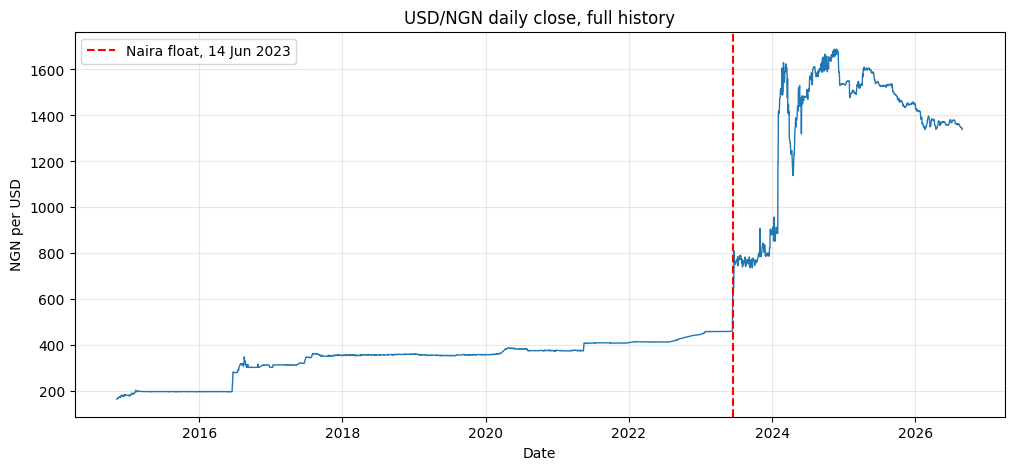

In [3]:
FLOAT_DATE = pd.Timestamp("2023-06-14")

plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["USDNGN_close"], linewidth=1)
plt.axvline(FLOAT_DATE, color="red", linestyle="--", linewidth=1.5, label="Naira float, 14 Jun 2023")
plt.title("USD/NGN daily close, full history")
plt.xlabel("Date")
plt.ylabel("NGN per USD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Why this matters for modeling, not just for the chart

A model trained on the full 2014-2026 history would spend most of its training data learning the behavior of a managed peg: long flat stretches punctuated by rare, enormous step jumps. That is a fundamentally different data-generating process from the floating regime the naira operates under today. A pattern like "the rate hasn't moved in 200 days, therefore it probably won't move tomorrow" was true under the peg and is false now.

**Decision: restrict the modeling dataset to the post-float period (June 15, 2023 onward).** This is the regime the model actually needs to work in, since it's the one you'd be using it in. The pre-float years stay in the dataframe for now since lag features computed near the boundary still need a few prior rows, but get filtered out once the target and features are built.

This is exactly the kind of thing worth a sentence in your executive summary's *Solution* section, and it's the strongest evidence you have that you understood your data rather than just running a pipeline on it.

## 3. Feature engineering

Same categories of feature discussed in the project plan, built programmatically so they'd work on any similarly-shaped time series, not hardcoded to specific dates.

- **Lag features:** the rate and oil price 1/3/7/14 days ago
- **Rolling statistics:** 7-day and 14-day rolling mean/std of the closing rate, and rolling std of the daily return (volatility)
- **Rate of change:** percentage change over 3/7/14-day windows, for both the exchange rate and Brent crude
- **Calendar features:** day of week, month

**On WTI vs. Brent:** Nigerian crude (Bonny Light) is priced relative to Brent, not WTI, so Brent is the more directly relevant benchmark here. The two are correlated at roughly 0.99 in this dataset (unsurprising, they're both global crude benchmarks), which means including both invites multicollinearity, mainly a concern for Logistic Regression, less so for the tree-based models in Stage 3. Both are kept for now since tree models handle it fine, flagged here so it isn't a silent gap.

In [4]:
for lag in [1, 3, 7, 14]:
    df[f"USDNGN_close_lag{lag}"] = df["USDNGN_close"].shift(lag)
    df[f"wti_price_lag{lag}"] = df["wti_price"].shift(lag)

for window in [7, 14]:
    df[f"USDNGN_close_roll_mean{window}"] = df["USDNGN_close"].rolling(window).mean()
    df[f"USDNGN_close_roll_std{window}"] = df["USDNGN_close"].rolling(window).std()
    df[f"daily_return_roll_std{window}"] = df["daily_return_pct"].rolling(window).std()

for window in [3, 7, 14]:
    df[f"USDNGN_pct_change_{window}d"] = df["USDNGN_close"].pct_change(periods=window) * 100
    df[f"brent_pct_change_{window}d"] = df["brent_price"].pct_change(periods=window) * 100

df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

print("Total columns after feature engineering:", df.shape[1])

Total columns after feature engineering: 32


## 4. Define the target

`target = 1` if the rate is more than 1% higher (naira weaker) 7 trading days from now, `target = 0` otherwise. This is a forward-looking label, so it needs `shift(-7)`, and the last 7 rows of the dataset will have no valid target since there's no future data for them yet, those get dropped.

If your actual class balance below comes out badly skewed (worse than roughly 85/15), that's a signal to revisit `THRESHOLD_PCT` or `HORIZON` rather than push ahead, an unusable imbalance here will just resurface as a broken model in Stage 3.

In [5]:
HORIZON = 7
THRESHOLD_PCT = 1.0

future_close = df["USDNGN_close"].shift(-HORIZON)
df["future_pct_change"] = (future_close / df["USDNGN_close"] - 1) * 100
df["target"] = (df["future_pct_change"] > THRESHOLD_PCT).astype(int)

df_labeled = df.dropna(subset=["future_pct_change"]).copy()
print("Labeled rows (full history):", df_labeled.shape[0])

Labeled rows (full history): 2802


### Class balance: full history vs. the post-float modeling window

Worth checking both, not just the one you'll actually train on, because the difference between them is itself informative. The peg years spent most of their time flat, so "weakens by more than 1% in a week" was a rare event there. Under the float, sustained depreciation has been closer to the norm, so expect these two numbers to look meaningfully different.

In [6]:
print("Full-history class balance:")
print(df_labeled["target"].value_counts(normalize=True).rename("share").round(3))

post_float = df_labeled[df_labeled["date"] >= FLOAT_DATE].copy()

print("\nPost-float modeling window:", post_float.shape[0], "rows")
print("Post-float class balance:")
print(post_float["target"].value_counts(normalize=True).rename("share").round(3))

Full-history class balance:
target
0    0.865
1    0.135
Name: share, dtype: float64

Post-float modeling window: 821 rows
Post-float class balance:
target
0    0.727
1    0.273
Name: share, dtype: float64


## 5. Final cleanup and save

Drop any rows where a lag/rolling feature is still `NaN` (this only affects the first ~14 rows of the *entire* series, back in 2014, so it should have no effect on the post-float window, confirmed below rather than assumed).

In [7]:
feature_cols = [c for c in post_float.columns if c not in ["date", "future_pct_change", "target"]]
na_before = post_float[feature_cols].isna().sum().sum()
print("NaN feature values in the post-float window before cleanup:", na_before)

post_float_clean = post_float.dropna(subset=feature_cols).reset_index(drop=True)
print("Final shape:", post_float_clean.shape)

NaN feature values in the post-float window before cleanup: 0
Final shape: (821, 34)


In [8]:
os.makedirs("processed_data", exist_ok=True)
post_float_clean.to_csv("processed_data/naira_pulse_features.csv", index=False)
print("Saved processed_data/naira_pulse_features.csv:", post_float_clean.shape)
print("\nFeature columns:")
for c in feature_cols:
    print(" -", c)

Saved processed_data/naira_pulse_features.csv: (821, 34)

Feature columns:
 - USDNGN_open
 - USDNGN_high
 - USDNGN_low
 - USDNGN_close
 - wti_price
 - brent_price
 - us_inflation_pct
 - daily_return_pct
 - rolling_volatility_7d
 - USDNGN_close_lag1
 - wti_price_lag1
 - USDNGN_close_lag3
 - wti_price_lag3
 - USDNGN_close_lag7
 - wti_price_lag7
 - USDNGN_close_lag14
 - wti_price_lag14
 - USDNGN_close_roll_mean7
 - USDNGN_close_roll_std7
 - daily_return_roll_std7
 - USDNGN_close_roll_mean14
 - USDNGN_close_roll_std14
 - daily_return_roll_std14
 - USDNGN_pct_change_3d
 - brent_pct_change_3d
 - USDNGN_pct_change_7d
 - brent_pct_change_7d
 - USDNGN_pct_change_14d
 - brent_pct_change_14d
 - day_of_week
 - month


## 6. Sanity-check the labels visually

Plot the post-float rate with the weeks flagged `target = 1` marked, this should visibly cluster around the periods where the rate was climbing, not be scattered randomly. If it looks random, that's a sign something is off in the target logic before moving to Stage 3.

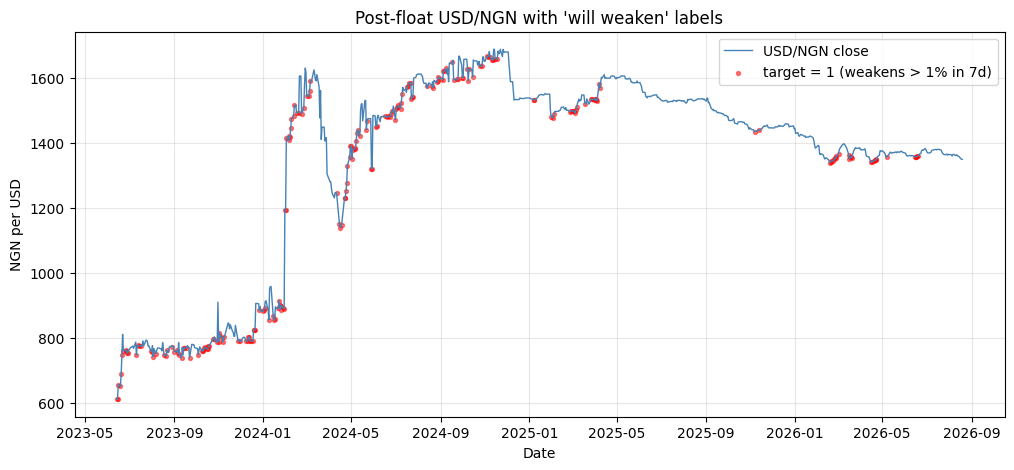

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(post_float_clean["date"], post_float_clean["USDNGN_close"], linewidth=1, color="steelblue", label="USD/NGN close")

flagged = post_float_clean[post_float_clean["target"] == 1]
ax.scatter(flagged["date"], flagged["USDNGN_close"], color="red", s=8, alpha=0.5, label="target = 1 (weakens > 1% in 7d)")

ax.set_title("Post-float USD/NGN with 'will weaken' labels")
ax.set_xlabel("Date")
ax.set_ylabel("NGN per USD")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 7. Stage 2 checklist

- [x] Identified and explicitly handled the June 2023 regime change, rather than training on a decade of two different currency regimes blended together
- [x] Lag, rolling, rate-of-change, and calendar features engineered
- [x] Noted the WTI/Brent collinearity and why Brent is the more relevant benchmark for Nigeria
- [x] Target defined as a forward-looking 7-day, >1% threshold classification label
- [x] Class balance checked on both the full history and the actual modeling window, and the difference explained rather than glossed over
- [x] Clean, model-ready dataset saved to `processed_data/naira_pulse_features.csv`

**Feeds into your Executive Summary's *Solution/Product* section:** this is where you can write a sentence like "the model is trained only on post-float data, since Nigeria's exchange rate regime fundamentally changed in June 2023" — that single sentence signals real analytical judgment, not just pipeline execution.

**Next: Stage 3** loads `processed_data/naira_pulse_features.csv`, builds the `ColumnTransformer` + `Pipeline` structure, and compares the baseline against Logistic Regression, Random Forest, Gradient Boosting, XGBoost, and LightGBM using `TimeSeriesSplit` cross-validation.
